# 👁️ Eye State CNN — Hyperparameter Tuning (Synapse)

**الهدف:** نحسّن الـ **baseline CNN** (الأفضل لحد هلأ: 97.46% accuracy، 96.1% recall للـ closed) عن طريق
البحث عن أفضل hyperparameters بدل ما نختارهم بإيدنا.

**النتائج لحد هلأ:**
| النموذج | Accuracy | Recall closed | Params |
|---|---|---|---|
| Baseline CNN | **97.46%** | **96.1%** | 304K |
| MobileNetV2 + Fine-tuning | 95.55% | 93.7% | 2.26M |

> MobileNetV2 كان أضعف بسبب اختلاف الـ domain (ImageNet ملوّن ↔ MRL صور Infrared رمادية)، فاعتمدنا الـ baseline.

**خطوات النوتبوك:**
1. **Hyperband search** بـ Keras Tuner على الـ train/val.
2. **إعادة تدريب** أفضل إعدادات بشكل كامل.
3. **Threshold tuning** على الـ val (لرفع recall العيون المسكّرة).
4. **تقييم نهائي** على الـ test + مقارنة مع الـ baseline.

## 1) تجهيز البيئة
نفس الـ baseline بالضبط (نفس الـ loader والـ splits) ← المقارنة عادلة. وبنثبّت `keras-tuner`.

In [1]:
!pip install -q keras-tuner
import os, sys, json, glob
if not os.path.exists("Synapse"):
    !git clone -q https://github.com/ManarAbu-Irsheid/Synapse.git
sys.path.insert(0, "Synapse/data_pipeline")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import keras_tuner as kt
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from dataset import make_dataset

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__, "| KerasTuner:", kt.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | KerasTuner: 1.4.8
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2) الإعدادات
- `MAX_EPOCHS = 15`: أقصى عدد epochs لأي تجربة أثناء البحث.
- `FACTOR = 3`: Hyperband بيبدأ تجارب كثيرة بـ epochs قليلة، وبيكمّل بس أفضل **ثلث** منها لمرحلة أطول.
- `FINAL_EPOCHS = 40`: لإعادة تدريب أفضل إعدادات (مع EarlyStopping).

In [2]:
SPLITS       = "Synapse/data_pipeline/splits"
OUT          = "/kaggle/working/eye_cnn_tuned"
IMG_SIZE     = 64
BATCH        = 64
MAX_EPOCHS   = 15
FACTOR       = 3
FINAL_EPOCHS = 40
CLASS_NAMES  = ["closed", "open"]
os.makedirs(OUT, exist_ok=True)

## 3) الداتا (مع الخلط الكامل)
نفس تصليح الـ baseline: ملف الـ train مرتّب حسب الفئة، فبنخلطه كامل قبل الـ loader.

In [3]:
dfs = {s: pd.read_csv(f"{SPLITS}/mrl_{s}.csv") for s in ["train", "val", "test"]}
missing = [p for p in dfs["train"].path.head(20) if not os.path.exists(p)]
assert not missing, f"المسارات مش موجودة! ضيفي MRL Eye Dataset كـ Input. مثال: {missing[0]}"

os.makedirs("/kaggle/working/splits_shuffled", exist_ok=True)
TRAIN_CSV = "/kaggle/working/splits_shuffled/mrl_train.csv"
dfs["train"].sample(frac=1, random_state=42).to_csv(TRAIN_CSV, index=False)
lab = pd.read_csv(TRAIN_CSV).label.values
n = min(10, len(lab) // BATCH)
print(f"نسبة open بأول {n} batches بعد الخلط:", lab[:n * BATCH].reshape(n, BATCH).mean(1).round(2))

train_ds = make_dataset(TRAIN_CSV, training=True, batch_size=BATCH, size=IMG_SIZE)
val_ds   = make_dataset(f"{SPLITS}/mrl_val.csv",  training=False, batch_size=BATCH, size=IMG_SIZE)
test_ds  = make_dataset(f"{SPLITS}/mrl_test.csv", training=False, batch_size=BATCH, size=IMG_SIZE)
print("✅ الداتا جاهزة")

نسبة open بأول 10 batches بعد الخلط: [0.5  0.56 0.41 0.66 0.56 0.58 0.45 0.48 0.52 0.47]
✅ الداتا جاهزة


## 4) فضاء البحث (Search Space)
نفس معمارية الـ baseline، بس بدل الأرقام الثابتة، بنعطي Keras Tuner **مدى** لكل hyperparameter:

| Hyperparameter | قيمة الـ baseline | المدى يلي بنجربه | ليش؟ |
|---|---|---|---|
| `base_filters` | 32 | 16، 32، 48 | سعة النموذج (فلاتر البلوك الأول، وبعدها ×2 و×4) |
| `conv_dropout` | 0.20–0.30 | 0.1 → 0.4 | قوة الـ regularization بالبلوكات |
| `dense_units` | 128 | 64، 128، 256 | حجم طبقة الـ Dense |
| `dense_dropout` | 0.5 | 0.3 → 0.6 | regularization قبل المخرج |
| `l2` | 1e-4 | 1e-5، 1e-4، 1e-3 | عقوبة الأوزان الكبيرة |
| `lr` | 1e-3 | 1e-4 → 3e-3 (log) | سرعة التعلم — أهم hyperparameter |

**الهدف (objective):** أقل `val_loss` — الـ val set أشخاص مختلفين عن الـ train، فهو مقياس صادق للتعميم.
> ⚠️ **الـ test set ما بنلمسه أبداً أثناء البحث** — لو اخترنا الإعدادات حسب الـ test، النتيجة النهائية بتصير متفائلة وغير صادقة.

In [4]:
METRICS = ["accuracy", keras.metrics.Precision(name="precision"),
           keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")]

def build_model(hp):
    f      = hp.Choice("base_filters", [16, 32, 48])
    drop_c = hp.Float("conv_dropout", 0.1, 0.4, step=0.05)
    units  = hp.Choice("dense_units", [64, 128, 256])
    drop_d = hp.Float("dense_dropout", 0.3, 0.6, step=0.1)
    l2     = hp.Choice("l2", [1e-5, 1e-4, 1e-3])
    lr     = hp.Float("lr", 1e-4, 3e-3, sampling="log")

    inp = keras.Input((IMG_SIZE, IMG_SIZE, 1), name="eye_gray")
    x = inp
    for mult in (1, 2, 4):                        # 3 بلوكات: f, 2f, 4f
        for _ in range(2):
            x = layers.Conv2D(f * mult, 3, padding="same", use_bias=False,
                              kernel_regularizer=regularizers.l2(l2))(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(drop_c)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(drop_d)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_open")(x)
    model = keras.Model(inp, out, name="eye_cnn_tuned")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=METRICS)
    return model

## 5) البحث بـ Hyperband
**ليش Hyperband وليس Grid أو Random؟** بيبدأ تجارب كثيرة لعدد epochs قليل، وبيوقف الضعيفة بكير، وبيعطي وقت أطول للواعدة بس ← نفس جودة البحث بوقت أقل بكثير.

⏱️ متوقع ياخذ تقريباً **ساعة** على GPU.

In [5]:
tuner = kt.Hyperband(
    build_model,
    objective=kt.Objective("val_loss", direction="min"),
    max_epochs=MAX_EPOCHS,
    factor=FACTOR,
    seed=42,
    directory="/kaggle/working/tuner",
    project_name="eye_cnn",
    overwrite=True,
)
tuner.search_space_summary()

tuner.search(train_ds, validation_data=val_ds,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3)],
             verbose=2)

Trial 30 Complete [00h 05m 20s]
val_loss: 0.13466209173202515

Best val_loss So Far: 0.08241432160139084
Total elapsed time: 01h 43m 00s


## 6) نتائج البحث
جدول بأفضل 10 تجارب — مفيد للتقرير (بيبين شو أثّر على الأداء).

In [6]:
rows = []
for t in tuner.oracle.get_best_trials(num_trials=10):
    r = dict(t.hyperparameters.values)
    r["val_loss"] = t.score
    rows.append(r)
trials = pd.DataFrame(rows).drop(columns=[c for c in ["tuner/epochs", "tuner/initial_epoch",
                                                      "tuner/bracket", "tuner/round", "tuner/trial_id"]
                                          if c in rows[0]], errors="ignore")
trials.to_csv(f"{OUT}/top_trials.csv", index=False)
display(trials)

best_hp = tuner.get_best_hyperparameters(1)[0]
best_values = {k: best_hp.values[k] for k in ["base_filters", "conv_dropout", "dense_units",
                                              "dense_dropout", "l2", "lr"]}
print("\n🏆 أفضل إعدادات:", json.dumps(best_values, indent=2))

,base_filters,conv_dropout,dense_units,dense_dropout,l2,lr,val_loss
0,32,0.15,128,0.4,0.00001,0.000722,0.082414
1,16,0.15,256,0.4,0.00010,0.001515,0.091124
2,48,0.30,256,0.5,0.00001,0.000721,0.097663
3,16,0.10,256,0.4,0.00010,0.002182,0.098062
4,32,0.10,256,0.4,0.00010,0.000292,0.098540
5,48,0.15,64,0.4,0.00001,0.000541,0.099733
6,32,0.15,128,0.4,0.00001,0.000722,0.100029
7,16,0.10,256,0.4,0.00010,0.002182,0.104147
8,16,0.15,256,0.4,0.00010,0.001515,0.109565
9,32,0.30,256,0.4,0.00001,0.000583,0.110134



🏆 أفضل إعدادات: {
  "base_filters": 32,
  "conv_dropout": 0.15000000000000002,
  "dense_units": 128,
  "dense_dropout": 0.4,
  "l2": 1e-05,
  "lr": 0.00072182541156161
}


## 7) إعادة تدريب أفضل إعدادات بشكل كامل
**ليش نعيد التدريب؟** أثناء البحث كل تجربة تدربت لـ 15 epoch كحد أقصى. هلأ بنعطي أفضل إعدادات فرصة كاملة (لحد 40 epoch) مع نفس الـ callbacks تبع الـ baseline.

Model: "eye_cnn_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ eye_gray (InputLayer)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 304,417 (1.16 MB)

 Trainable params: 303,521 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/40
865/865 ━━━━━━━━━━━━━━━━━━━━ 50s 47ms/step - accuracy: 0.8810 - auc: 0.9720 - loss: 0.2538 - precision: 0.9282 - recall: 0.8782 - val_accuracy: 0.8546 - val_auc: 0.9686 - val_loss: 0.5183 - val_precision: 0.9972 - val_recall: 0.7043 - learning_rate: 7.2183e-04
Epoch 2/40
865/865 ━━━━━━━━━━━━━━━━━━━━ 31s 36ms/step - accuracy: 0.9757 - auc: 0.9962 - loss: 0.0759 - precision: 0.9762 - recall: 0.9769 - val_accuracy: 0.9524 - val_auc: 0.9908 - val_loss: 0.1368 - val_precision: 0.9727 - val_recall: 0.9287 - learning_rate: 7.2183e-04
Epoch 3/40
865/865 ━━━━━━━━━━━━━━━━━━━━ 31s 36ms/step - accuracy: 0.9811 - auc: 0.9976 - loss: 0.0607 - precision: 0.9814 - recall: 0.9820 - val_accuracy: 0.9295 - val_auc: 0.9900 - val_loss: 0.1912 - val_precision: 0.8842 - val_recall: 0.9847 - learning_rate: 7.2183e-04
Epoch 4/40
865/865 ━━━━━━━━━━━━━━━━━━━━ 31s 36ms/step - accuracy: 0.9825 - auc: 0.9978 - loss: 0.0565 - precision: 0.9819 - recall: 0.9844 - val_accuracy: 0.9712 - val_auc: 0.9956 - va

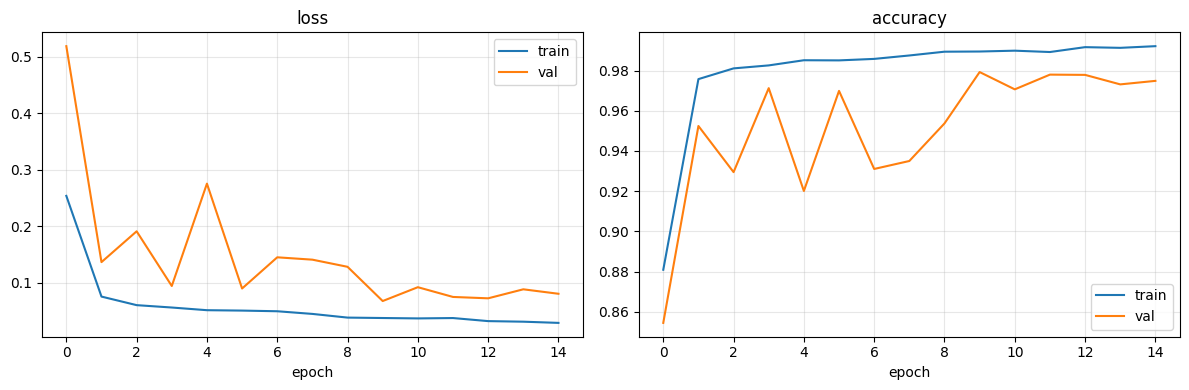

In [7]:
tf.keras.utils.set_random_seed(42)
model = tuner.hypermodel.build(best_hp)
model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(f"{OUT}/best.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger(f"{OUT}/history.csv"),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=FINAL_EPOCHS, callbacks=callbacks)

h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="train"); ax[i].plot(h[f"val_{m}"], label="val")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 8) Threshold Tuning (على الـ val)
النموذج بيطلع `p_open` (احتمال إن العين مفتوحة). افتراضياً: لو `p_open < 0.5` ← مسكّرة.

**المشكلة:** أغلب أخطاء الـ baseline كانت **عيون مسكّرة انصنّفت مفتوحة** (126 مقابل 28) — وهاد أخطر خطأ لكشف النعاس.

**الحل:** نرفع الـ threshold (مثلاً 0.6) ← بنصنّف عيون أكثر كـ "مسكّرة" ← **recall الـ closed بيرتفع** (مقابل إنذارات خاطئة أكثر شوي).

بنختار الـ threshold يلي بيعطي أعلى **F2-score لفئة closed** على الـ **val** (F2 بتعطي الـ recall وزن ضعف الـ precision).
> الـ threshold كمان hyperparameter، فبنختاره على الـ val مش الـ test.

In [8]:
y_val      = dfs["val"].label.values
p_open_val = model.predict(val_ds, verbose=0).ravel()

def closed_scores(y, p_open, t):
    pred = (p_open >= t).astype(int)                     # 1 = open, 0 = closed
    pr, rc, _, _ = precision_recall_fscore_support(y, pred, labels=[0], zero_division=0)
    f2 = 5 * pr[0] * rc[0] / (4 * pr[0] + rc[0] + 1e-9)
    return pr[0], rc[0], f2, (pred == y).mean()

ths = np.round(np.arange(0.30, 0.91, 0.05), 2)
sweep = pd.DataFrame([dict(zip(["threshold", "closed_precision", "closed_recall", "closed_F2", "accuracy"],
                               (t, *closed_scores(y_val, p_open_val, t)))) for t in ths])
BEST_T = float(sweep.loc[sweep.closed_F2.idxmax(), "threshold"])
sweep.to_csv(f"{OUT}/threshold_sweep_val.csv", index=False)
display(sweep.style.format("{:.4f}").highlight_max(subset=["closed_F2"]))
print(f"🎯 الـ threshold المختار (من الـ val): {BEST_T}")

,threshold,closed_precision,closed_recall,closed_F2,accuracy
0,0.3000,0.9862,0.9611,0.9660,0.9732
1,0.3500,0.9845,0.9671,0.9706,0.9754
2,0.4000,0.9830,0.9728,0.9748,0.9775
3,0.4500,0.9814,0.9775,0.9782,0.9790
4,0.5000,0.9791,0.9804,0.9801,0.9792
5,0.5500,0.9769,0.9830,0.9818,0.9794
6,0.6000,0.9743,0.9858,0.9835,0.9794
7,0.6500,0.9711,0.9883,0.9848,0.9790
8,0.7000,0.9672,0.9898,0.9852,0.9777
9,0.7500,0.9636,0.9913,0.9857,0.9764


🎯 الـ threshold المختار (من الـ val): 0.75


## 9) التقييم النهائي على الـ Test Set
بنعرض النتائج **مرتين**: بالـ threshold الافتراضي (0.5) عشان المقارنة العادلة مع الـ baseline، وبالـ threshold المختار.

===== threshold = 0.5 =====
              precision    recall  f1-score   support

      closed     0.9921    0.9367    0.9636      3222
        open     0.9325    0.9916    0.9611      2844

    accuracy                         0.9624      6066
   macro avg     0.9623    0.9641    0.9624      6066
weighted avg     0.9642    0.9624    0.9624      6066

===== threshold = 0.75 =====
              precision    recall  f1-score   support

      closed     0.9716    0.9652    0.9684      3222
        open     0.9609    0.9680    0.9644      2844

    accuracy                         0.9665      6066
   macro avg     0.9662    0.9666    0.9664      6066
weighted avg     0.9666    0.9665    0.9665      6066



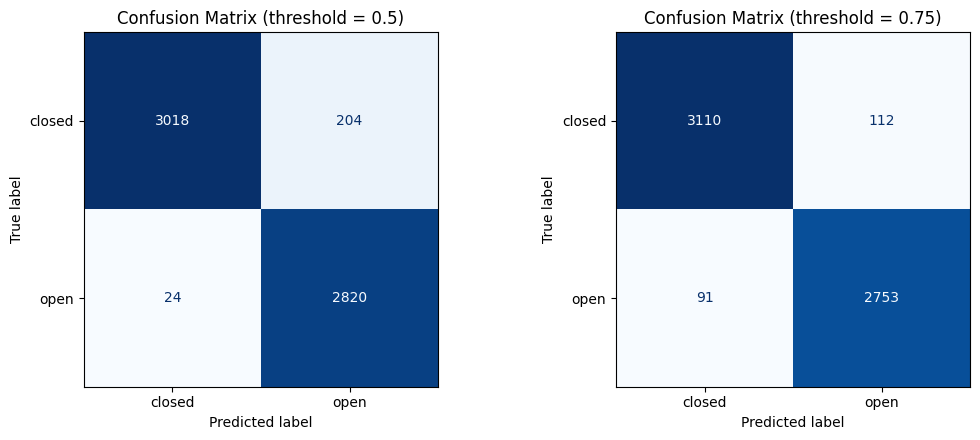

In [9]:
y_true = dfs["test"].label.values
p_open = model.predict(test_ds, verbose=0).ravel()
test_eval = model.evaluate(test_ds, verbose=0, return_dict=True)

results = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for i, t in enumerate([0.5, BEST_T]):
    y_pred = (p_open >= t).astype(int)
    rep = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
    cm = confusion_matrix(y_true, y_pred)
    print(f"===== threshold = {t} =====")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[i], cmap="Blues", colorbar=False)
    ax[i].set_title(f"Confusion Matrix (threshold = {t})")
    results[str(t)] = {
        "accuracy": rep["accuracy"],
        "closed": {k: rep["closed"][k] for k in ["precision", "recall", "f1-score", "support"]},
        "open":   {k: rep["open"][k]   for k in ["precision", "recall", "f1-score", "support"]},
        "confusion_matrix": cm.tolist(),
    }
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

## 10) حفظ النموذج والنتائج

In [10]:
model.save(f"{OUT}/eye_cnn_tuned.keras")
model.save_weights(f"{OUT}/eye_cnn_tuned.weights.h5")

metrics = {
    "model": "eye_cnn_tuned",
    "params": int(model.count_params()),
    "epochs_trained": len(h),
    "best_val_loss": float(h.val_loss.min()),
    "test_auc": float(test_eval["auc"]),
    "test_accuracy": results["0.5"]["accuracy"],
    "closed": results["0.5"]["closed"],
    "open": results["0.5"]["open"],
    "confusion_matrix": results["0.5"]["confusion_matrix"],
    "chosen_threshold": BEST_T,
    "at_chosen_threshold": results[str(BEST_T)],
    "best_hyperparameters": best_values,
    "search": {"algorithm": "Hyperband", "max_epochs": MAX_EPOCHS, "factor": FACTOR,
               "objective": "val_loss", "trials": len(tuner.oracle.trials)},
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("\nFiles:", sorted(os.listdir(OUT)))

{
  "model": "eye_cnn_tuned",
  "params": 304417,
  "epochs_trained": 15,
  "best_val_loss": 0.06800558418035507,
  "test_auc": 0.9953749775886536,
  "test_accuracy": 0.9624134520276953,
  "closed": {
    "precision": 0.9921104536489151,
    "recall": 0.9366852886405959,
    "f1-score": 0.9636015325670498,
    "support": 3222.0
  },
  "open": {
    "precision": 0.9325396825396826,
    "recall": 0.9915611814345991,
    "f1-score": 0.9611451942740287,
    "support": 2844.0
  },
  "confusion_matrix": [
    [
      3018,
      204
    ],
    [
      24,
      2820
    ]
  ],
  "chosen_threshold": 0.75,
  "at_chosen_threshold": {
    "accuracy": 0.9665347840422024,
    "closed": {
      "precision": 0.971571383942518,
      "recall": 0.9652389819987586,
      "f1-score": 0.9683948310758212,
      "support": 3222.0
    },
    "open": {
      "precision": 0.9609075043630018,
      "recall": 0.9680028129395218,
      "f1-score": 0.9644421089507794,
      "support": 2844.0
    },
    "confusion

## 11) مقارنة مع الـ Baseline
**اختياري:** لو ضفتي output نوتبوك `eye-CNN-training` كـ Input، الخلية بتلاقي metrics الـ baseline لحالها.

In [11]:
found = glob.glob("/kaggle/input/**/eye_cnn_baseline/metrics.json", recursive=True)
if not found:
    print("ما لقيت metrics الـ baseline — ضيفي output نوتبوك eye-CNN-training كـ Input لو بدك المقارنة.")
else:
    b = json.load(open(found[0]))
    rows = [
        {"model": "baseline (t=0.5)", "params": b["params"], "accuracy": b["test_accuracy"], "auc": b["test_auc"],
         "closed_recall": b["closed"]["recall"], "closed_precision": b["closed"]["precision"],
         "missed_closed": b["confusion_matrix"][0][1]},
        {"model": "tuned (t=0.5)", "params": metrics["params"], "accuracy": metrics["test_accuracy"],
         "auc": metrics["test_auc"], "closed_recall": metrics["closed"]["recall"],
         "closed_precision": metrics["closed"]["precision"], "missed_closed": metrics["confusion_matrix"][0][1]},
        {"model": f"tuned (t={BEST_T})", "params": metrics["params"],
         "accuracy": metrics["at_chosen_threshold"]["accuracy"], "auc": metrics["test_auc"],
         "closed_recall": metrics["at_chosen_threshold"]["closed"]["recall"],
         "closed_precision": metrics["at_chosen_threshold"]["closed"]["precision"],
         "missed_closed": metrics["at_chosen_threshold"]["confusion_matrix"][0][1]},
    ]
    cmp = pd.DataFrame(rows).set_index("model")
    cmp.to_csv(f"{OUT}/comparison_vs_baseline.csv")
    display(cmp)

,params,accuracy,auc,closed_recall,closed_precision,missed_closed
model,,,,,,
baseline (t=0.5),304417,0.974613,0.996700,0.960894,0.991037,126
tuned (t=0.5),304417,0.962413,0.995375,0.936685,0.992110,204
tuned (t=0.75),304417,0.966535,0.995375,0.965239,0.971571,112


## 12) الاستخدام بالـ real-time
```python
model = keras.models.load_model("eye_cnn_tuned.keras")
p_open = model.predict(preprocess_eye(eye_roi_bgr)[None], verbose=0)[0, 0]
eye_closed = p_open < THRESHOLD     # القيمة من metrics.json ← chosen_threshold
```